# Differentiation in Neural Networks: simple graphs
Each graph uses the same 3 steps:
1. make the x values with a **range**: `x = np.arange(start, stop, step)`
2. calculate `y` (the function) and `dy` (its derivative) from the whole array at once
3. plot both with `plt.plot`

Change the range or the numbers and run the cell again.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt



def draw(x, y, dy, title):
    plt.plot(x, y,  label="S(x)  (function)")
    plt.plot(x, dy, "--", label="S'(x)  (derivative)")
    plt.title(title); plt.xlabel("x"); plt.grid(alpha=0.3); plt.legend()
    plt.show()

## 1. What is a derivative? (slope)
For f(x) = x², the derivative is 2x. At x = 1 the slope is 2.

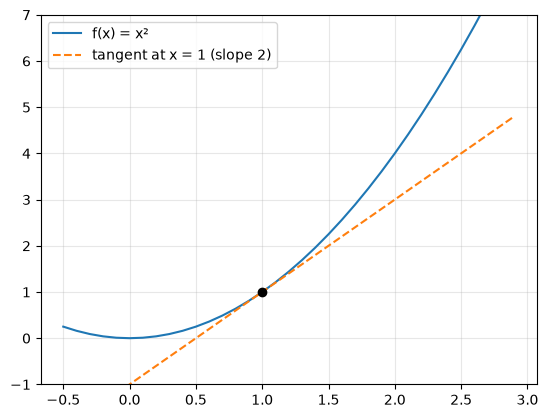

In [56]:
x = np.arange(-0.5, 3, 0.1)          # x from -0.5 to 3, step 0.1
y = x ** 2                            # f(x)
slope = 2 * 1                         # f'(1) = 2x at x = 1
tangent = slope * (x - 1) + 1         # straight line touching the curve at x = 1

plt.plot(x, y, label="f(x) = x²")
plt.plot(x, tangent, "--", label="tangent at x = 1 (slope 2)")
plt.plot(1, 1, "ko")
plt.ylim(-1, 7); plt.grid(alpha=0.3); plt.legend(); plt.show()

## 2. Step function
The derivative is **0 everywhere**, so it gives no signal to learn from.

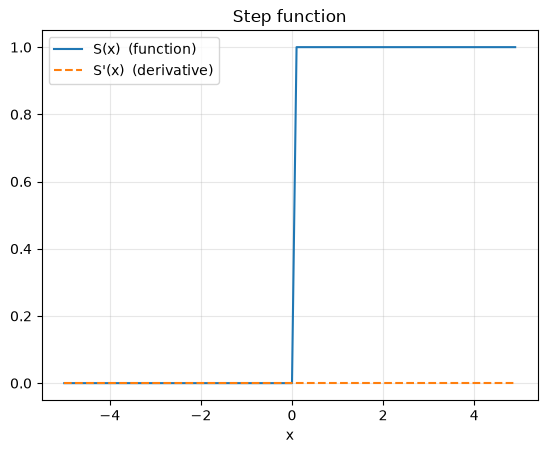

In [ ]:
x  = np.arange(-5, 5, 0.1)
y  = np.where(x >= 0, 1, 0)           # 1 if x >= 0 else 0
dy = np.zeros(len(x))                 # derivative is 0
draw(x, y, dy, "Step function")

## 3. Ramp function
Slope is 0.5 between 0 and 2, and 0 outside.

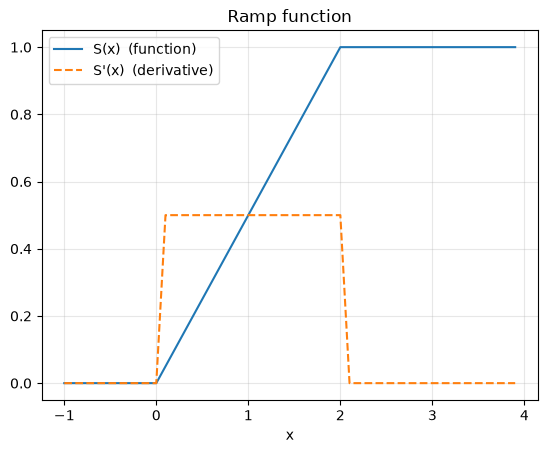

In [ ]:
x  = np.arange(-1, 4, 0.1)
y  = np.clip(0.5 * x, 0, 1)                    # 0, then 0.5x, then 1
dy = np.where((x > 0) & (x < 2), 0.5, 0)       # 0.5 inside the ramp
draw(x, y, dy, "Ramp function")

## 4. Sigmoid
**Derivative = S(x) · (1 − S(x))**, maximum 0.25 at x = 0.

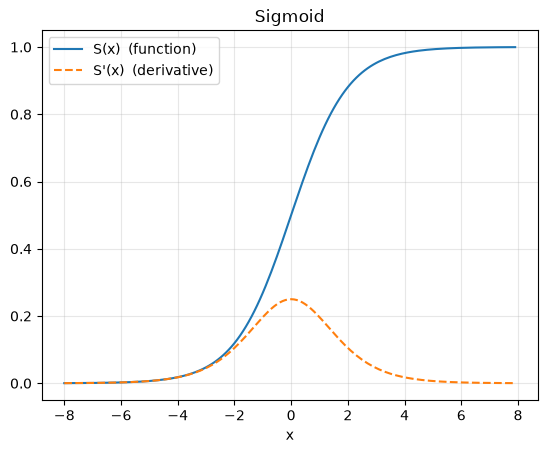

Sigmoid slope at some x values
x = 0   S = 0.5   S' = 0.25
x = 0.3   S = 0.574   S' = 0.2445
x = 2   S = 0.881   S' = 0.105
x = 5   S = 0.993   S' = 0.0066


In [ ]:
x  = np.arange(-8, 8, 0.1)
y  = 1 / (1 + np.exp(-x))
dy = y * (1 - y)
draw(x, y, dy, "Sigmoid")

print("Sigmoid slope at some x values")
for v in [0, 0.3, 2, 5]:
    s = 1 / (1 + np.exp(-v))
    print("x =", v, "  S =", round(s, 3), "  S' =", round(s * (1 - s), 4))

**Gain λ** makes the sigmoid steeper. Derivative = λ · S · (1 − S), maximum λ / 4.

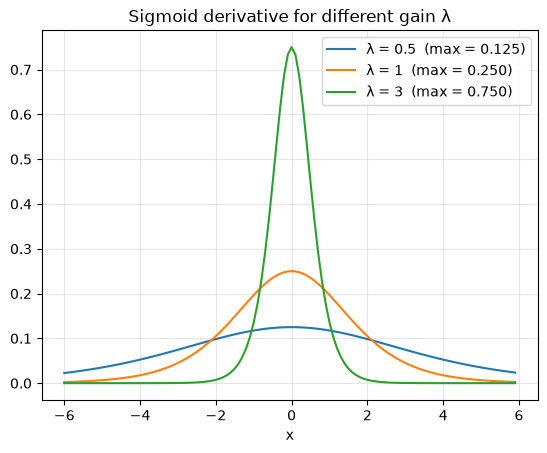

In [ ]:
x = np.arange(-6, 6, 0.1)
for lam in [0.5, 1, 3]:
    s  = 1 / (1 + np.exp(-lam * x))
    ds = lam * s * (1 - s)
    plt.plot(x, ds, label=f"λ = {lam}  (max = {ds.max():.3f})")
plt.title("Sigmoid derivative for different gain λ"); plt.xlabel("x"); plt.grid(alpha=0.3); plt.legend(); plt.show()

## 5. Tanh
**Derivative = 1 − tanh²(x)**, maximum 1 at x = 0.

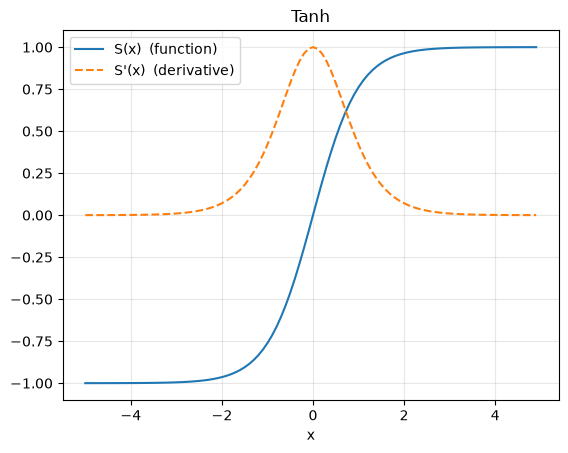

Tanh slope at x = 0.3: 0.9151   (sigmoid: 0.2445)


In [ ]:
x  = np.arange(-5, 5, 0.1)
y  = np.tanh(x)
dy = 1 - y ** 2


draw(x, y, dy, "Tanh")

print("Tanh slope at x = 0.3:", round(1 - np.tanh(0.3) ** 2, 4), "  (sigmoid: 0.2445)")

## 6. ReLU
Derivative is **1** when x > 0 and **0** when x < 0.

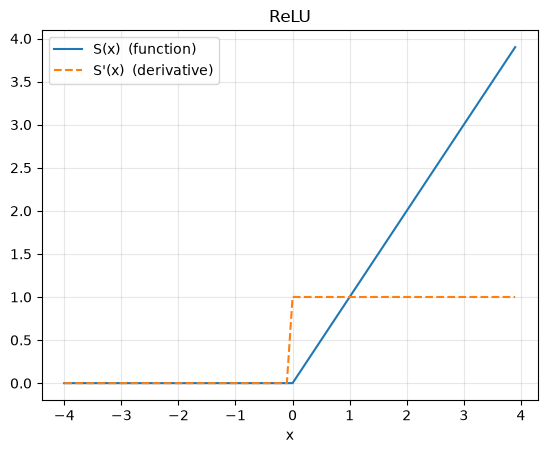

In [ ]:
x  = np.arange(-4, 4, 0.1)
y  = np.maximum(0, x)
dy = np.where(x > 0, 1, 0)
draw(x, y, dy, "ReLU")

## 7. Leaky ReLU
The negative side has a small slope `a`, so the derivative is never exactly 0.

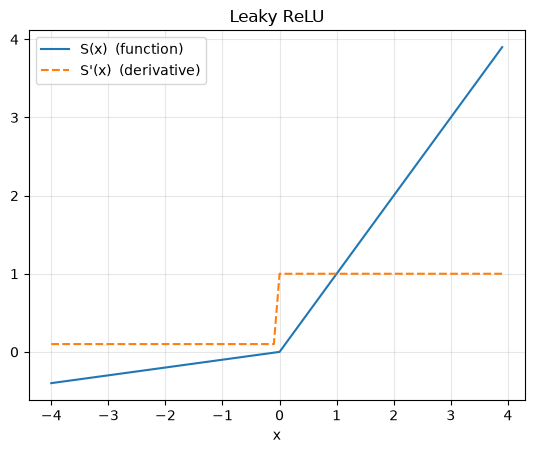

In [ ]:
a  = 0.1                              # usually 0.01; 0.1 so it is easy to see
x  = np.arange(-4, 4, 0.1)
y  = np.where(x > 0, x, a * x)
dy = np.where(x > 0, 1, a)
draw(x, y, dy, "Leaky ReLU")

## 8. Gaussian
Derivative = −(x − c) / σ² · S(x). It is 0 at the peak (x = c).

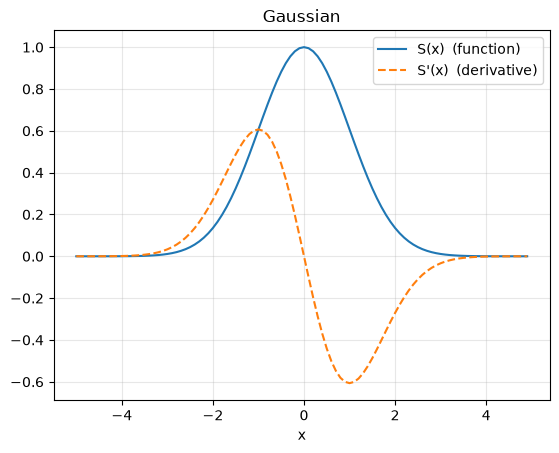

In [ ]:
c, sigma = 0, 1
x  = np.arange(-5, 5, 0.1)
y  = np.exp(-(x - c) ** 2 / (2 * sigma ** 2))
dy = -(x - c) / sigma ** 2 * y
draw(x, y, dy, "Gaussian")

## 9. Softmax
Softmax works on a whole list of numbers. Its derivative is a small table (matrix): **S_k · (1 if k = l else 0 − S_l)**.

In [ ]:
x = np.array([2.0, 1.0, 0.1])
S = np.exp(x) / np.exp(x).sum()
print("softmax =", S.round(3), " sum =", S.sum())

J = np.diag(S) - np.outer(S, S)        # derivative matrix
print("derivative matrix:")
print(J.round(3))
print("each row sums to:", J.sum(axis=1).round(6))

softmax = [0.659 0.242 0.099]  sum = 1.0
derivative matrix:
[[ 0.225 -0.16  -0.065]
 [-0.16   0.184 -0.024]
 [-0.065 -0.024  0.089]]
each row sums to: [0. 0. 0.]


## 10. All derivatives together

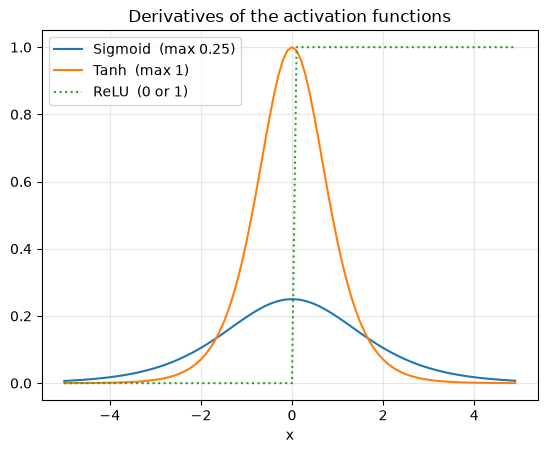

In [ ]:
x = np.arange(-5, 5, 0.1)
sig = 1 / (1 + np.exp(-x))

plt.plot(x, sig * (1 - sig),        label="Sigmoid  (max 0.25)")
plt.plot(x, 1 - np.tanh(x) ** 2,    label="Tanh  (max 1)")
plt.plot(x, np.where(x > 0, 1, 0), ":", label="ReLU  (0 or 1)")
plt.title("Derivatives of the activation functions"); plt.xlabel("x")
plt.grid(alpha=0.3); plt.legend(); plt.show()